### 1. Imports and data

In [1]:
import os, time, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Kaggle input and output directories
INPUT_DIR = "/kaggle/input"
RESULTS_DIR = "/kaggle/working/bean_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Find the Dry Bean file anywhere under Kaggle inputs
candidate_files = []
for pattern in ("*.xlsx", "*.xls", "*.csv"):
    candidate_files.extend(
        glob.glob(os.path.join(INPUT_DIR, "**", pattern), recursive=True)
    )

preferred = [
    f for f in candidate_files
    if "dry_bean_dataset" in os.path.basename(f).lower()
]
if preferred:
    DATA_PATH = preferred[0]
elif candidate_files:
    DATA_PATH = candidate_files[0]
else:
    raise FileNotFoundError(
        "No CSV/Excel file found under /kaggle/input. "
        "Use Add Input to attach the Dry Bean Dataset."
    )

TARGET_COL = None  # automatically detect the target column (Class)

print("Dataset file:", DATA_PATH)
print("Result directory:", RESULTS_DIR)

# Load dataset
if DATA_PATH.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(DATA_PATH)
else:
    df = pd.read_csv(DATA_PATH)

df.columns = [str(c).strip() for c in df.columns]

if TARGET_COL is None:
    lower = {c.lower(): c for c in df.columns}
    for cand in ["quality", "class", "target", "label", "customer_segment",
                 "cultivar", "wine", "type"]:
        if cand in lower:
            TARGET_COL = lower[cand]
            break
    else:
        TARGET_COL = df.columns[-1]

print("shape:", df.shape, "| label column:", TARGET_COL)
print(df[TARGET_COL].value_counts().sort_index())


Dataset file: /kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx
Result directory: /kaggle/working/bean_results
shape: (13611, 17) | label column: Class
Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1928
SEKER       2027
SIRA        2636
Name: count, dtype: int64


### 2. Split, imputation and scaling

In [2]:
y_raw = df[TARGET_COL].values
id_cols = [c for c in df.columns if c.lower() in ("id", "unnamed: 0")]
feat = df.drop(columns=[TARGET_COL] + id_cols)
feat = pd.get_dummies(feat, dtype=float)             # text columns (e.g. wine type) become numeric
FEATURE_NAMES = list(feat.columns)

# classes with fewer than 10 samples cannot be split 60/20/20 reliably, so they are dropped
vals, counts = np.unique(y_raw, return_counts=True)
keep = vals[counts >= 10]
if len(keep) < len(vals):
    print("WARNING: dropped rare classes:", [v for v in vals if v not in keep])
mask = np.isin(y_raw, keep)
X = feat.values[mask].astype(float)
y_raw = y_raw[mask]

classes = np.unique(y_raw)                            # original labels, sorted
y = np.searchsorted(classes, y_raw)                   # 0 .. K-1
N_CLASSES = len(classes)
print(f"samples={len(y)} | features={X.shape[1]} | classes={classes.tolist()}")

# 60% train / 20% validation / 20% test (stratified)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

imputer = SimpleImputer(strategy="median").fit(X_train)       # fitted on train only (handles missing values)
scaler = StandardScaler().fit(imputer.transform(X_train))     # fitted on train only
prep = lambda A: scaler.transform(imputer.transform(A))
X_train, X_val, X_test = prep(X_train), prep(X_val), prep(X_test)

Y_train, Y_val, Y_test = np.eye(N_CLASSES)[y_train], np.eye(N_CLASSES)[y_val], np.eye(N_CLASSES)[y_test]
for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} | size={len(yy):5d} | per-class={np.bincount(yy, minlength=N_CLASSES)}")

samples=13611 | features=16 | classes=['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
train | size= 8166 | per-class=[ 793  313  978 2128 1156 1216 1582]
val   | size= 2722 | per-class=[264 105 326 709 386 405 527]
test  | size= 2723 | per-class=[265 104 326 709 386 406 527]


### 3. Core functions (shared by all optimizers)

In [3]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def cross_entropy(Y, P):
    """Multi-class cross-entropy (this is the 'Loss')."""
    return float(-np.mean(np.sum(Y * np.log(np.clip(P, 1e-15, 1.0)), axis=1)))

def gradients(X, Y, P):
    err = P - Y
    return X.T @ err / len(X), err.mean(axis=0)

def class_metrics(y_true, proba):
    pred = proba.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, pred)), "precision": float(p),
            "recall": float(r), "f1": float(f1),
            "loss": cross_entropy(np.eye(N_CLASSES)[y_true], proba)}

### 4. Stochastic Gradient Descent (SGD) implementation

In [4]:
def train(Xtr, Ytr, Xv, Yv, lr, epochs, seed=0):
    rng = np.random.default_rng(seed)
    W = np.zeros((Xtr.shape[1], Ytr.shape[1])); b = np.zeros(Ytr.shape[1])
    hist = {"train": [], "val": []}
    n = len(Xtr)
    t0 = time.time()
    for ep in range(epochs):
        for i in rng.permutation(n):
            xi = Xtr[i]
            p = softmax((xi @ W + b)[None, :])[0]
            err = p - Ytr[i]
            W -= lr * np.outer(xi, err)
            b -= lr * err
        hist["train"].append(cross_entropy(Ytr, softmax(Xtr @ W + b)))
        hist["val"].append(cross_entropy(Yv, softmax(Xv @ W + b)))
    return W, b, hist, time.time() - t0

### 5. Forest utilities: bootstrap, random features, voting

In [5]:
N_MODELS = 15                                  # base learners in the forest
N_SUB = max(2, X_train.shape[1] // 2)          # random subset of features per learner (half of the features)

def train_ensemble(train_fn, lr, epochs, n_models=N_MODELS, n_sub=N_SUB, seed=0):
    """Random-Forest style ensemble: each learner gets a bootstrap sample and a random feature subset."""
    rng = np.random.default_rng(seed)
    n, d = X_train.shape
    models, hists, total_time = [], [], 0.0
    for m in range(n_models):
        idx = rng.integers(0, n, n)                                   # bootstrap sample
        feats = np.sort(rng.choice(d, size=n_sub, replace=False))     # random features
        W, b, h, t = train_fn(X_train[idx][:, feats], Y_train[idx], X_val[:, feats], Y_val, lr, epochs, seed=m)
        models.append((feats, W, b)); hists.append(h); total_time += t
    return models, hists, total_time

def learner_proba(model, X):
    feats, W, b = model
    return softmax(X[:, feats] @ W + b)

def ensemble_proba(models, X):
    return np.mean([learner_proba(m, X) for m in models], axis=0)     # soft voting

def hard_vote(models, X):
    votes = np.zeros((len(X), N_CLASSES))
    for m in models:
        votes[np.arange(len(X)), learner_proba(m, X).argmax(axis=1)] += 1
    return votes.argmax(axis=1)                                       # majority voting

def run_grid(train_fn, lrs, epochs):
    """Learning rate chosen by validation loss of a single full-feature model (test set untouched)."""
    runs = {}
    print(f"{'lr':>9s} | {'train loss':>10s} | {'val loss':>10s} | {'time(s)':>8s}")
    for lr in lrs:
        W, b, h, t = train_fn(X_train, Y_train, X_val, Y_val, lr, epochs, seed=0)
        runs[lr] = h
        print(f"{lr:9.4f} | {h['train'][-1]:10.6f} | {h['val'][-1]:10.6f} | {t:8.2f}")
    score = lambda k: runs[k]["val"][-1] if np.isfinite(runs[k]["val"][-1]) else np.inf
    best = min(runs, key=score)
    print(f"\n>>> best lr = {best}")
    return best

def final_report(name, train_fn, lr, epochs):
    models, hists, total_time = train_ensemble(train_fn, lr, epochs)
    val_proba, test_proba = ensemble_proba(models, X_val), ensemble_proba(models, X_test)

    indiv_acc = [accuracy_score(y_test, learner_proba(m, X_test).argmax(axis=1)) for m in models]
    soft = class_metrics(y_test, test_proba)
    hard_pred = hard_vote(models, X_test)
    hp, hr, hf, _ = precision_recall_fscore_support(y_test, hard_pred, average="macro", zero_division=0)
    hard = {"accuracy": float(accuracy_score(y_test, hard_pred)), "precision": float(hp), "recall": float(hr), "f1": float(hf)}

    print(f"Single learners (test acc): mean={np.mean(indiv_acc):.4f} std={np.std(indiv_acc):.4f} "
          f"min={np.min(indiv_acc):.4f} max={np.max(indiv_acc):.4f}")
    print(f"\n{'':14s} {'Accuracy':>9s} {'Precision':>10s} {'Recall':>8s} {'F1':>8s} {'Loss':>8s}")
    print(f"{'Soft voting':14s} {soft['accuracy']:9.4f} {soft['precision']:10.4f} {soft['recall']:8.4f} {soft['f1']:8.4f} {soft['loss']:8.4f}")
    print(f"{'Hard voting':14s} {hard['accuracy']:9.4f} {hard['precision']:10.4f} {hard['recall']:8.4f} {hard['f1']:8.4f} {'--':>8s}")
    print(f"training time (all {len(models)} learners): {total_time:.1f}s")

    out = {"name": name, "lr": lr, "epochs": epochs, "n_models": len(models), "n_features_per_model": N_SUB,
           "time_s": total_time, "single_acc_mean": float(np.mean(indiv_acc)), "single_acc_std": float(np.std(indiv_acc)),
           "test_soft": soft, "test_hard": hard,
           "val_soft": class_metrics(y_val, val_proba),
           "loss_train": np.mean([h["train"] for h in hists], axis=0).tolist(),
           "loss_val": np.mean([h["val"] for h in hists], axis=0).tolist()}
    with open(os.path.join(RESULTS_DIR, f"{name}.json"), "w") as f:
        json.dump(out, f)
    np.savez(os.path.join(RESULTS_DIR, f"{name}_proba.npz"), val=val_proba, test=test_proba,
             y_val=y_val, y_test=y_test, classes=classes.astype(str))
    print(f"\nsaved -> {RESULTS_DIR}/{name}.json and {name}_proba.npz")
    return out

def plot_loss(res, title):
    plt.figure(figsize=(7, 4))
    plt.plot(res["loss_train"], label="train (own bootstrap sample)")
    plt.plot(res["loss_val"], "--", label="validation")
    plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title(title); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 6. Learning-rate search (validation loss)

In [6]:
EPOCHS = 10
LRS = [0.1, 0.03, 0.01]

best_lr = run_grid(train, LRS, EPOCHS)

       lr | train loss |   val loss |  time(s)
   0.1000 |   0.240729 |   0.216343 |     1.94
   0.0300 |   0.222378 |   0.201713 |     1.64
   0.0100 |   0.223508 |   0.203631 |     1.65

>>> best lr = 0.03


### 7. Train the forest, evaluate on the test set, save results

In [7]:
res = final_report("sgd", train, best_lr, EPOCHS)

Single learners (test acc): mean=0.9069 std=0.0102 min=0.8803 max=0.9166

                Accuracy  Precision   Recall       F1     Loss
Soft voting       0.9177     0.9351   0.9295   0.9317   0.2361
Hard voting       0.9155     0.9332   0.9271   0.9296       --
training time (all 15 learners): 24.6s

saved -> /kaggle/working/bean_results/sgd.json and sgd_proba.npz


### 8. Loss curves (mean over the base learners)

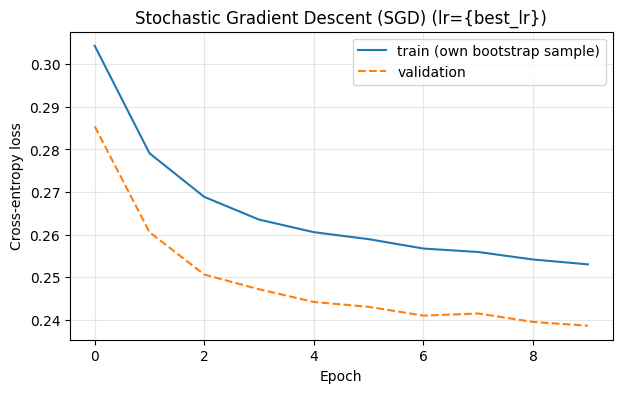

In [8]:
plot_loss(res, "Stochastic Gradient Descent (SGD) (lr={best_lr})")